In [ ]:
from microtorch.model_maker import ModelMaker
from microtool.microtorch import MicrotorchTissueModel
from microtool.tissue_model import MultiTissueModel, RelaxationTissueModel
from microtool.utils.unit_registry import unit

microtorch_model = ModelMaker("SphereBallAstrosticks")
sphere, ball, astrosticks = microtorch_model.compartments

# Keep the requested compartment settings.
sphere.fixed_D = 2
astrosticks.fixed_D_par = 8.0
astrosticks.parameter_ranges = [[8.0, 8.0]]

# Wrap each compartment individually, not the combined ModelMaker model.
sphere_model = MicrotorchTissueModel(
    sphere,
    parameters={"radius": 6.0},
)
ball_model = MicrotorchTissueModel(
    ball,
    parameters={"D": 2.0},
)
astrosticks_model = MicrotorchTissueModel(
    astrosticks,
    parameters={"D_par": 8.0},
)

# Hold these diffusivities fixed during fitting.
for compartment in (ball_model, astrosticks_model):
    for name in ("D", "D_par"):
        if name in compartment:
            compartment[name].optimize = False
            compartment[name].fit_flag = False

sphere_model["radius"].value_list = list(range(5, 16))

sphere_relax = RelaxationTissueModel(sphere_model, t2=50e-3 * unit("s"))
ball_relax = RelaxationTissueModel(ball_model, t2=100e-3 * unit("s"))
astrosticks_relax = RelaxationTissueModel(
    astrosticks_model,
    t2=100e-3 * unit("s"),
)

#These T2 values are used for prediction but not estimated or optimized.
for compartment in (sphere_relax, ball_relax, astrosticks_relax):
    compartment["T2"].optimize = True
    compartment["T2"].fit_flag = True


vfs = [0.6, 0.35]
vfs.append(1.0 - sum(vfs))

model = MultiTissueModel(
    [sphere_relax, ball_relax, astrosticks_relax],
    volume_fractions=vfs,
)

print(model)

No YAML configuration found for SphereBallAstrosticks model.
Falling back to parsing model name for compartments: ['Sphere', 'Ball', 'Astrosticks'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  SphereBallAstrosticks
########### Compartments: ['Sphere', 'Ball', 'Astrosticks']
########### Parameter names: [['radius'], ['D'], ['D_par']]
########### Parameter ranges: [[[0.001, 15]], [[0.001, 3]], [[0.5, 3.0]]]
-----------
Tissue model with 10 scalar parameters:
Tissue-parameter        Value    Scale  Optimize    Fit    Fit Bounds
--------------------  -------  -------  ----------  -----  -------------
model_0_model_radius     6       1      True        True   (0.001, 15.0)
model_0_T2               0.05    0.001  True        True   (0.0001, 1.0)
model_1_model_D          2       1      False       False  (0.001, 3.0)
model_1_T2               0.1     0.001  False       False  (0.0001, 1.0)
model_2_model_D_par      8       1      False       F

In [20]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling import sample_uniform_half_sphere

n_directions = 6
n_shells = 5
block_size = n_directions + 1  # b0 + n_directions

# shell_bvals = [1500, 1000, 2200, 2500, 2500]
# shell_deltas = [0.0258, 0.0205,0.0205,0.0334, 0.0334]
# shell_Deltas = [0.0434, 0.0431,0.0431, 0.0455, 0.0455]
# initial_te = 0.09


shell_bvals = [2999, 2000, 1500, 500, 90]
shell_deltas = [0.0247, 0.0132, 0.0247, 0.0122, 0.0122]
shell_Deltas = [0.0438, 0.0323, 0.0434, 0.0313, 0.0238]
initial_te = [0.090, 0.067, 0.090, 0.065, 0.050]
# Build the measurements in shell blocks: b0, then six directions.
b_vals_list = []
pulse_durations_list = []
pulse_intervals_list = []
echo_times_list = []

for i in range(n_shells):
    b_vals_list.append(0.0)
    b_vals_list.extend([shell_bvals[i]] * n_directions)

    pulse_durations_list.extend([shell_deltas[i]] * block_size)
    pulse_intervals_list.extend([shell_Deltas[i]] * block_size)
    echo_times_list.extend([initial_te[i]] * block_size)

b_vals = np.array(b_vals_list)
pulse_durations = np.array(pulse_durations_list)
pulse_intervals = np.array(pulse_intervals_list)
echo_times = np.array(echo_times_list)
directions = sample_uniform_half_sphere(len(b_vals))

initial_scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=b_vals,
    b_vectors=directions,
    pulse_durations=pulse_durations,
    pulse_intervals=pulse_intervals,
    echo_times=echo_times,
)

# One optimized TE, delta, and Delta per shell, shared across that shell's
# b0 and diffusion-weighted measurements.
for name in (
    "EchoTime",
    "DiffusionPulseDuration",
    "DiffusionPulseInterval",
):
    initial_scheme[name].set_repetition_period(block_size)

# Keep each b0 gradient magnitude fixed at zero.
# All diffusion-weighted gradient magnitudes remain independently optimizable.
b0_mask = np.isclose(b_vals, 0.0)
magnitude = initial_scheme["DiffusionPulseMagnitude"]
magnitude.set_fixed_mask(b0_mask)

magnitude.set_fixed_mask(b0_mask)
magnitude.set_repetition_period(n_directions)

# Check the masks and b0 values.
print("Timing free indices:",
      np.flatnonzero(initial_scheme["EchoTime"].optimize_mask))
print("Gradient-magnitude free indices:",
      np.flatnonzero(magnitude.optimize_mask))
print("b0 gradient magnitudes:", magnitude.values[b0_mask])

assert np.all(magnitude.values[b0_mask] == 0.0)
assert not np.any(magnitude.optimize_mask[b0_mask])

print(magnitude.optimize_mask)
print(initial_scheme)


Timing free indices: [ 0  7 14 21 28]
Gradient-magnitude free indices: [ 1  8 15 22 29]
b0 gradient magnitudes: [-0. -0. -0. -0. -0.]
[False  True False False False False False False  True False False False
 False False False  True False False False False False False  True False
 False False False False False  True False False False False False]
Acquisition scheme with 35 measurements and 6 scalar parameters. 
total number of optimized parameters is 20:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.078)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.001, 0.1)    DiffusionPulseInterval [s] in (0.001, 0.1)    EchoTime [s] in (0.001, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  --------------------------------------------  --------------------------------------------  ------------------------------
                  

In [21]:
from copy import deepcopy
import numpy as np

scheme = deepcopy(initial_scheme)
x0 = scheme.scaled_free_parameter_vector.copy()

for name, constraint in scheme.constraints.items():
    scheme.set_scaled_free_parameter_vector(x0)
    values = np.atleast_1d(constraint.fun(x0))
    print(
        name,
        "values:", values.shape,
        "lower bounds:", np.shape(constraint.lb),
        "upper bounds:", np.shape(constraint.ub),
    )

scheme.set_scaled_free_parameter_vector(x0)

PulseIntervalLargerThanPulseDuration values: (35,) lower bounds: () upper bounds: ()
PulseMagnitudeSmallerThanMaxMagnitude values: (35,) lower bounds: () upper bounds: ()
EchoTimeLargerThanMinEchoTime values: (35,) lower bounds: () upper bounds: ()
BValueWithinBounds values: (30,) lower bounds: () upper bounds: ()


In [22]:
signal = model(initial_scheme)
print(signal)

[0.2618072  0.08785724 0.08785724 0.08785724 0.08785724 0.08785724
 0.08785724 0.36179083 0.13448487 0.13448487 0.13448487 0.13448487
 0.13448487 0.13448487 0.2618072  0.10337632 0.10337632 0.10337632
 0.10337632 0.10337632 0.10337632 0.37233739 0.23267964 0.23267964
 0.23267964 0.23267964 0.23267964 0.23267964 0.46333993 0.41918392
 0.41918392 0.41918392 0.41918392 0.41918392 0.41918392]


In [23]:
jacobian = model.scaled_jacobian(initial_scheme)
print(jacobian)
print(jacobian.shape)

[[ 0.          0.00357046  0.16529889  0.40656966  0.40656966]
 [-0.00844032  0.00301773  0.13970961  0.0010098   0.07356084]
 [-0.00844032  0.00301773  0.13970961  0.0010098   0.07356084]
 [-0.00844032  0.00301773  0.13970961  0.0010098   0.07356084]
 [-0.00844032  0.00301773  0.13970961  0.0010098   0.07356084]
 [-0.00844032  0.00301773  0.13970961  0.0010098   0.07356084]
 [-0.00844032  0.00301773  0.13970961  0.0010098   0.07356084]
 [ 0.          0.00421048  0.26184567  0.51170858  0.51170858]
 [-0.01517503  0.00336436  0.20922659  0.00937227  0.11337248]
 [-0.01517503  0.00336436  0.20922659  0.00937227  0.11337248]
 [-0.01517503  0.00336436  0.20922659  0.00937227  0.11337248]
 [-0.01517503  0.00336436  0.20922659  0.00937227  0.11337248]
 [-0.01517503  0.00336436  0.20922659  0.00937227  0.11337248]
 [-0.01517503  0.00336436  0.20922659  0.00937227  0.11337248]
 [ 0.          0.00357046  0.16529889  0.40656966  0.40656966]
 [-0.00463791  0.00327928  0.15181831  0.02024191  0.10

In [24]:
from microtool.optimize import optimize_scheme

optimal_scheme, _ = optimize_scheme(initial_scheme, model, noise_variance=0.05, method="trust-constr", solver_options = {
    "verbose": 2,
    "maxiter": 1000,
    #"finite_diff_rel_step": 1e-8,  # Prevents large jumps during gradient estimation
    #"initial_tr_radius": 0.05        # Prevents trust radius from jumping to 35.0
})

RuntimeError: Initial AcquisitionScheme error: the initial acquisition scheme results in an ill conditioned Fisher information matrix, possibly due to model degeneracy. Try a different initial AcquisitionScheme, or alternatively simplify your TissueModel.

In [ ]:
import numpy as np
import pandas as pd


def get_unique_shells(scheme, scheme_name="Scheme"):
    df = pd.DataFrame(
        {
            "Scheme": scheme_name,
            "b_value": np.round(scheme.b_values, 1),
            "TE_ms": np.round(scheme.echo_times * 1e3, 2),
            "delta_ms": np.round(scheme.pulse_durations * 1e3, 2),
            "Delta_ms": np.round(scheme.pulse_intervals * 1e3, 2),
        }
    )

    # Filter out b = 0
    df_nonzero = df[df["b_value"] > 0]

    # Group by unique parameters and count directions
    shells = (
        df_nonzero.groupby(
            ["Scheme", "b_value", "TE_ms", "delta_ms", "Delta_ms"], as_index=False
        )
        .size()
        .rename(columns={"size": "N_directions"})
    )
    return shells


# Combine initial and optimal shells
shells_initial = get_unique_shells(initial_scheme, scheme_name="Initial")
shells_optimal = get_unique_shells(optimal_scheme, scheme_name="Optimal")

combined_shells = pd.concat([shells_initial, shells_optimal], ignore_index=True)

print(combined_shells.to_string(index=False))

 Scheme  b_value  TE_ms  delta_ms  Delta_ms  N_directions
Initial     90.0  50.00     12.20     23.80             6
Initial    500.0  65.00     12.20     31.30             6
Initial   1500.0  90.00     24.70     43.40             6
Initial   2000.0  67.00     13.20     32.30             6
Initial   2999.0  90.00     24.70     43.80             6
Optimal     61.5  33.39      8.45     17.57             6
Optimal    699.7  56.35     10.60     29.89             6
Optimal   1034.7  75.99     16.84     48.05             6
Optimal   1073.8  74.80     18.35     48.20             6
Optimal   1754.3  42.63     15.31     22.30             6


In [ ]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats


# loc is mean and scale is standard deviation
noise_distribution = stats.norm(loc=0, scale=0.02)

# Perform a Monte Carlo simulation using the initial scheme.
simulation = MonteCarloSimulation(
    initial_scheme,
    model,
    noise_distribution,
    n_sim=100,
    fit_options={"diff_step": 1e-4},
)
simulation.run()
initial = simulation.result

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(optimal_scheme)
simulation.run()
optimal = simulation.result

Starting Monte Carlo with 100 simulations:   0%|          | 0/100 [00:00<?, ?it/s]/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)
Starting Monte Carlo with 100 simulations:   1%|          | 1/100 [00:01<02:11,  1.33s/it]/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)
Starti

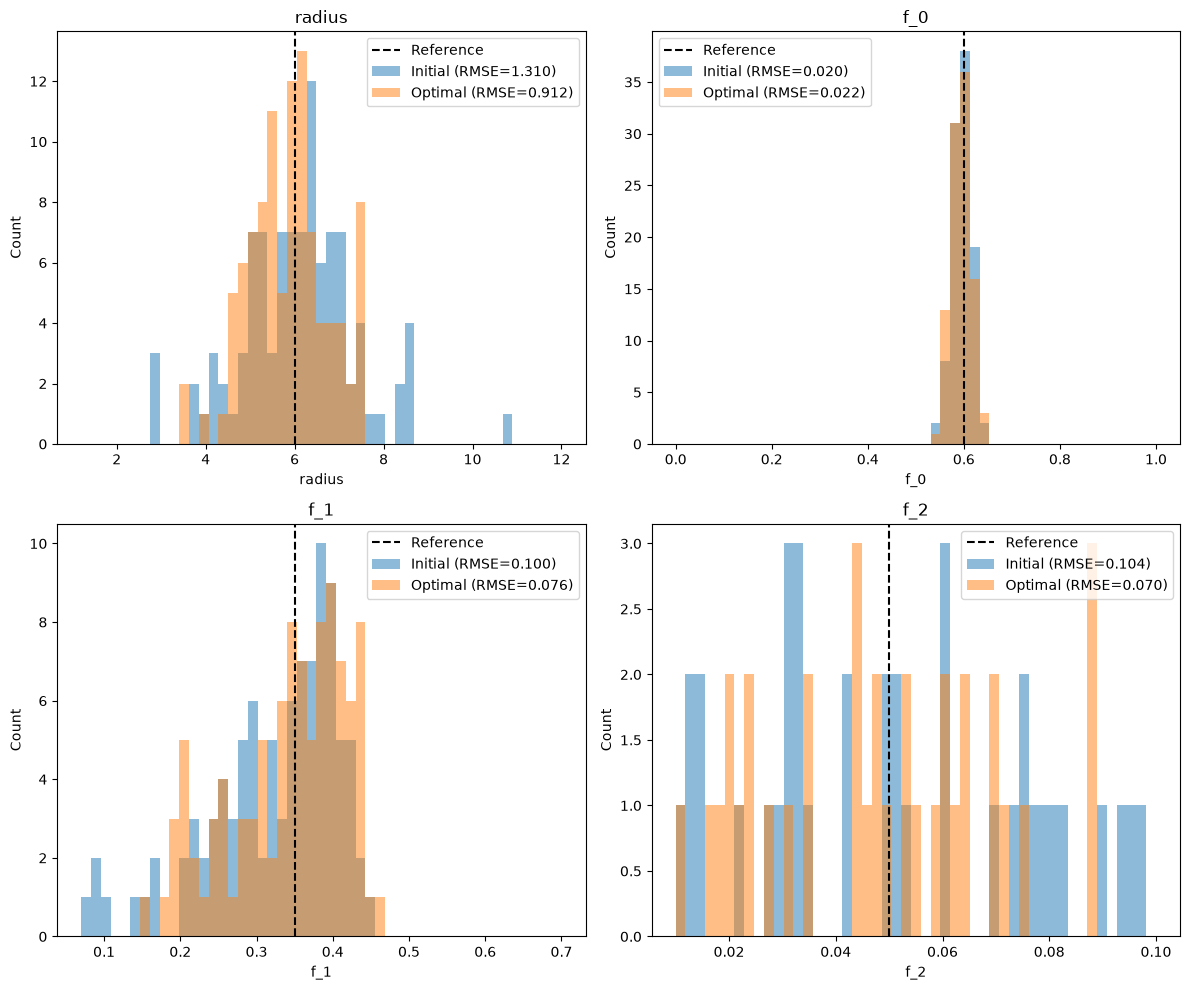

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

initial_result = initial
optimal_result = optimal

radius_key = "model_0_model_radius"

# Derived fraction f_0 = 1 - f_1 - f_2
initial_f0 = 1 - initial_result["vf_1"] - initial_result["vf_2"]
optimal_f0 = 1 - optimal_result["vf_1"] - optimal_result["vf_2"]
reference_f0 = model["vf_0"].value

radius_ref = model[radius_key].value
f1_ref = model["vf_1"].value
f2_ref = model["vf_2"].value

plots_data = [
    (
        "radius",
        radius_ref,
        initial_result[radius_key],
        optimal_result[radius_key],
        np.linspace(0.2 * radius_ref, 2 * radius_ref, 50),
    ),
    (
        "f_0",
        reference_f0,
        initial_f0,
        optimal_f0,
        np.linspace(0, 1, 50),
    ),
    (
        "f_1",
        f1_ref,
        initial_result["vf_1"],
        optimal_result["vf_1"],
        np.linspace(0.2 * f1_ref, 2 * f1_ref, 50),
    ),
    (
        "f_2",
        f2_ref,
        initial_result["vf_2"],
        optimal_result["vf_2"],
        np.linspace(0.2 * f2_ref, 2 * f2_ref, 50),
    ),
]

# Create 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (name, ref, init_vals, opt_vals, bins) in zip(axes, plots_data):
    init_rmse = np.sqrt(np.mean((init_vals - ref) ** 2))
    opt_rmse = np.sqrt(np.mean((opt_vals - ref) ** 2))

    ax.axvline(ref, color="black", linestyle="--", label="Reference")
    ax.hist(
        init_vals,
        bins=bins,
        alpha=0.5,
        label=f"Initial (RMSE={init_rmse:.3f})",
    )
    ax.hist(
        opt_vals,
        bins=bins,
        alpha=0.5,
        label=f"Optimal (RMSE={opt_rmse:.3f})",
    )

    ax.set_title(name)
    ax.set_xlabel(name)
    ax.set_ylabel("Count")
    ax.legend()

plt.tight_layout()
plt.show()